# Classification Track — Review 1 (Part A)
**Dataset:** Airline Passenger Satisfaction  
**Target:** `satisfaction` (satisfied / neutral or dissatisfied)  
**Algorithms (Part A):** Logistic Regression, K-Nearest Neighbors, Gaussian Naive Bayes, Decision Tree, Support Vector Machine

This notebook covers: dataset audit, EDA, cleaning, feature engineering, encoding/scaling/splitting,
and training + evaluating the five Part-A classification algorithms with a comparison table.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import CalibratedClassifierCV

RANDOM_STATE = 42

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_palette("colorblind")
plt.rcParams['figure.figsize'] = (8, 5)


## Section A — Dataset Audit & EDA

In [3]:
df = pd.read_csv("airlinepassenger.csv")
df = df.drop(columns=[c for c in ["Unnamed: 0", "id"] if c in df.columns])

print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nTarget distribution:\n", df['satisfaction'].value_counts())
print("\nTarget distribution (%):\n", df['satisfaction'].value_counts(normalize=True) * 100)


Shape: (25976, 23)

Dtypes:
 Gender                                   str
Customer Type                            str
Age                                    int64
Type of Travel                           str
Class                                    str
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Inflight service                       int64
Cleanliness                            int64
Departure Delay in Minutes             int64
Arrival Delay in Minutes  

**Observation:** The dataset has 25,976 rows and 23 usable columns after dropping the two
identifier columns (`Unnamed: 0`, `id`), which carry no predictive signal and would only add noise
if left in. The only missing values are in `Arrival Delay in Minutes` (83 rows, ~0.3%). The target
classes are reasonably balanced (~55% neutral/dissatisfied vs ~45% satisfied), so no resampling is required.

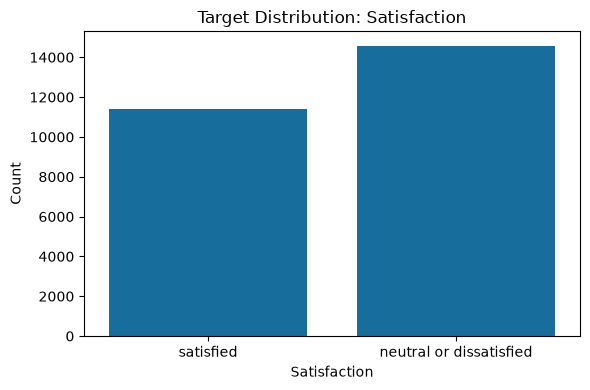

In [4]:
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=df, x='satisfaction', ax=ax)
ax.set_title("Target Distribution: Satisfaction")
ax.set_xlabel("Satisfaction")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig("target_distribution.png", bbox_inches="tight")
plt.show()


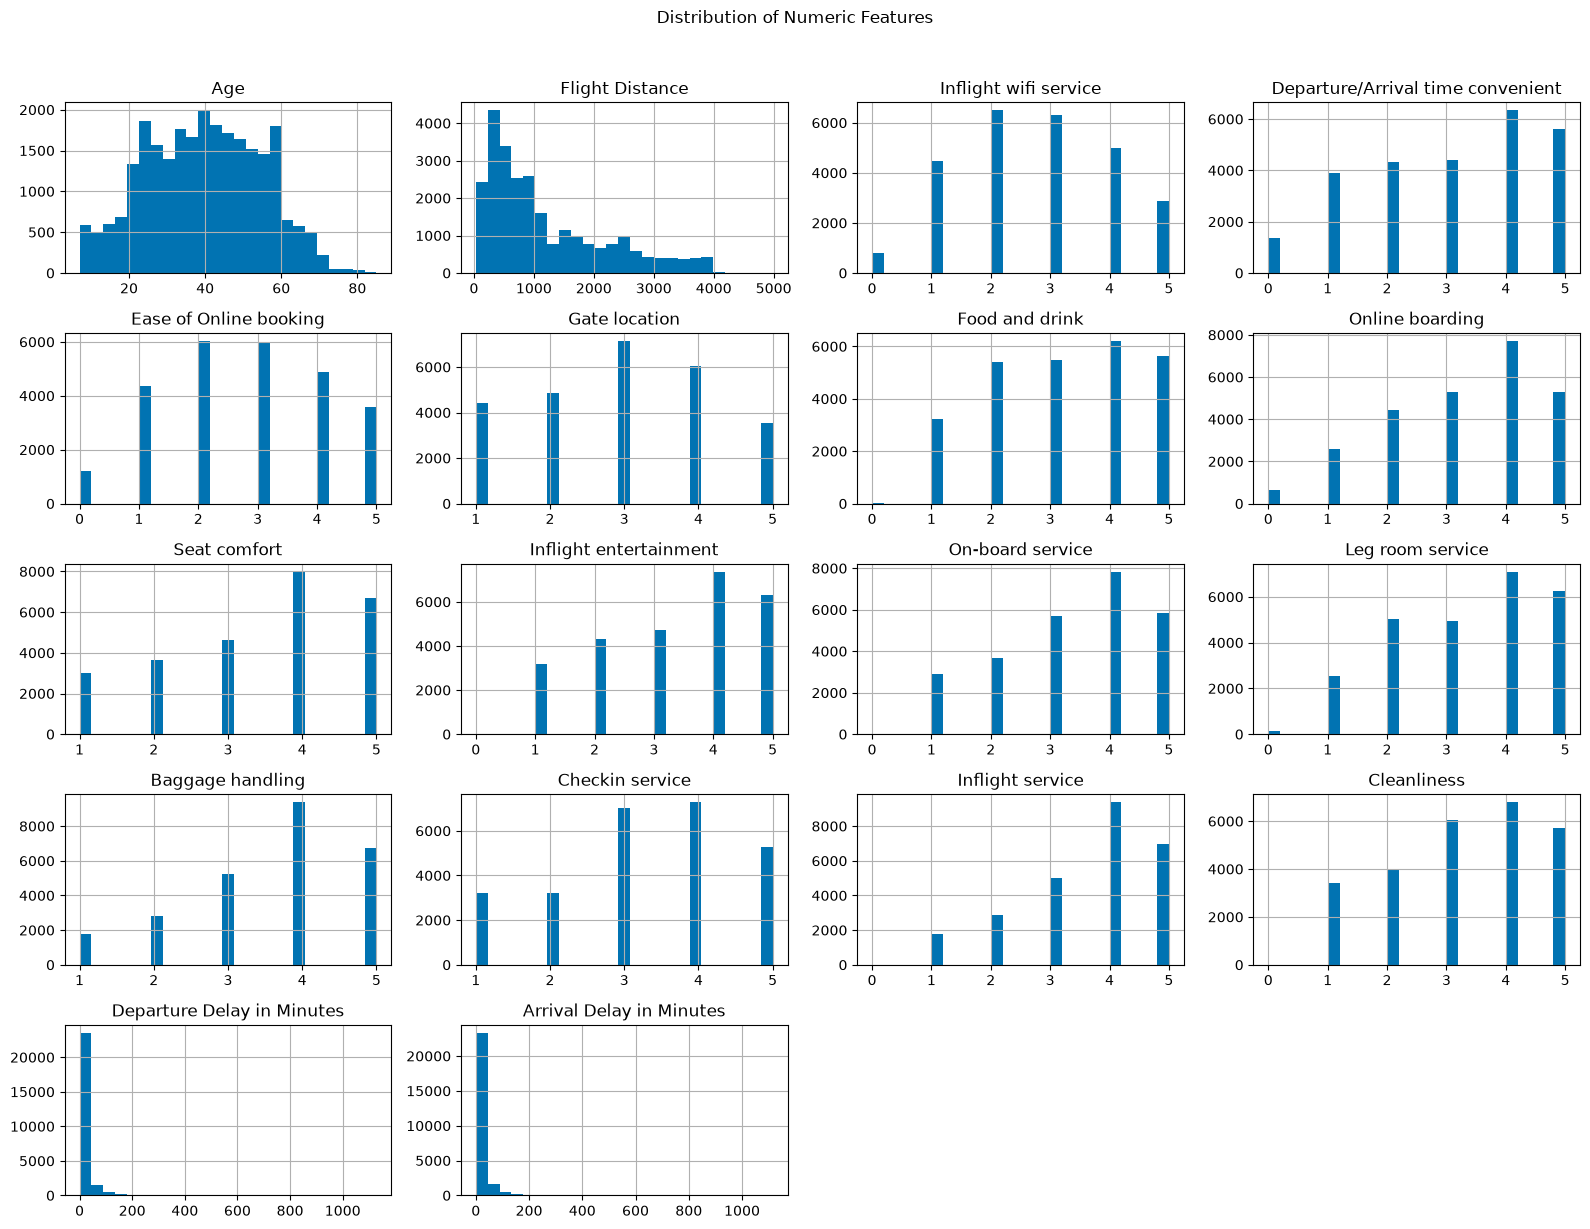

In [5]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df[numeric_cols].hist(figsize=(16, 12), bins=25)
plt.suptitle("Distribution of Numeric Features", y=1.02)
plt.tight_layout()
plt.savefig("feature_distributions.png", bbox_inches="tight")
plt.show()


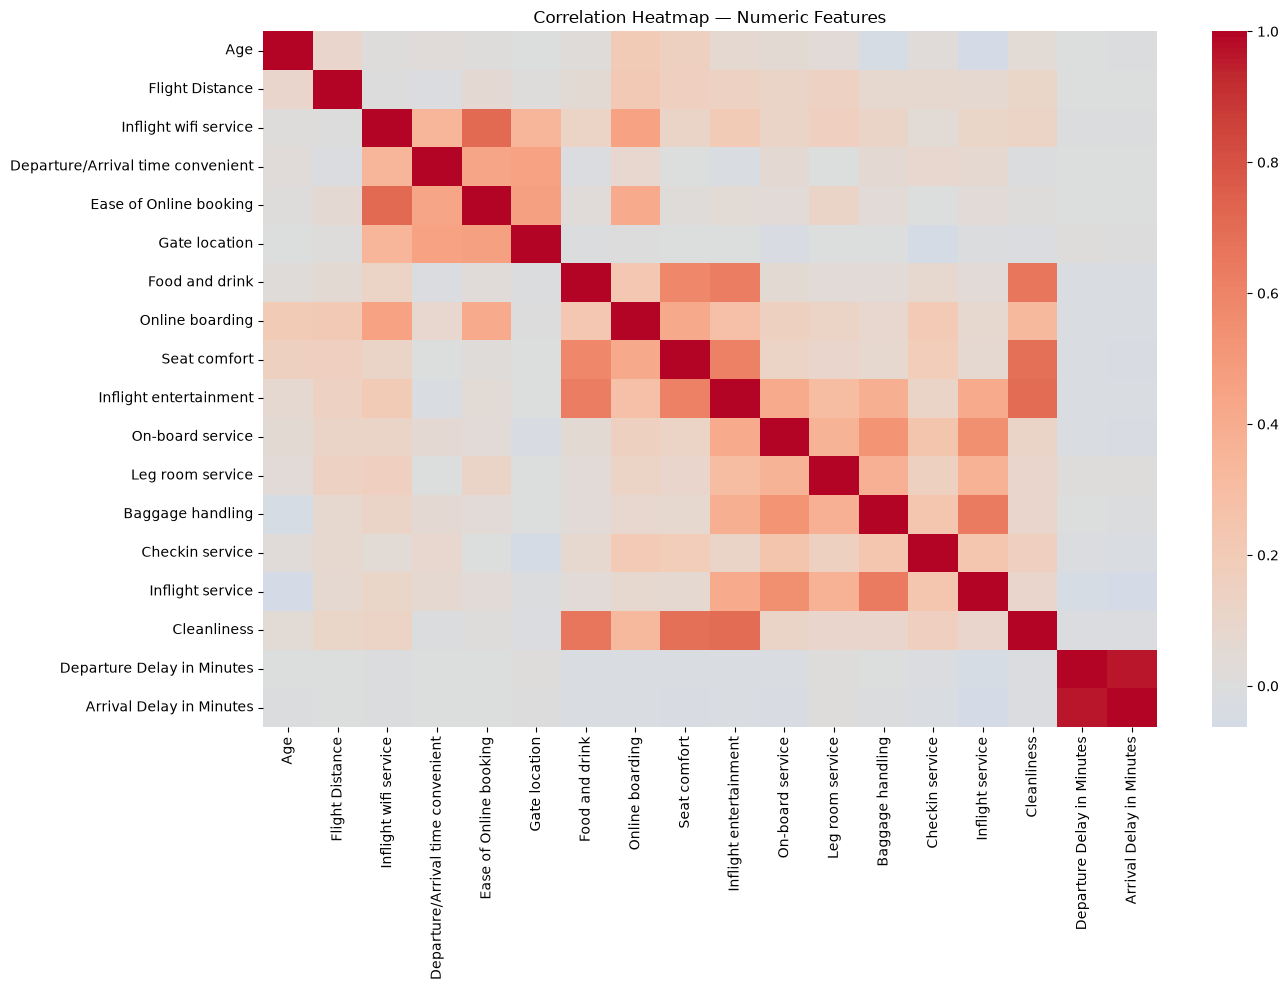

In [6]:
plt.figure(figsize=(14, 10))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Numeric Features")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", bbox_inches="tight")
plt.show()


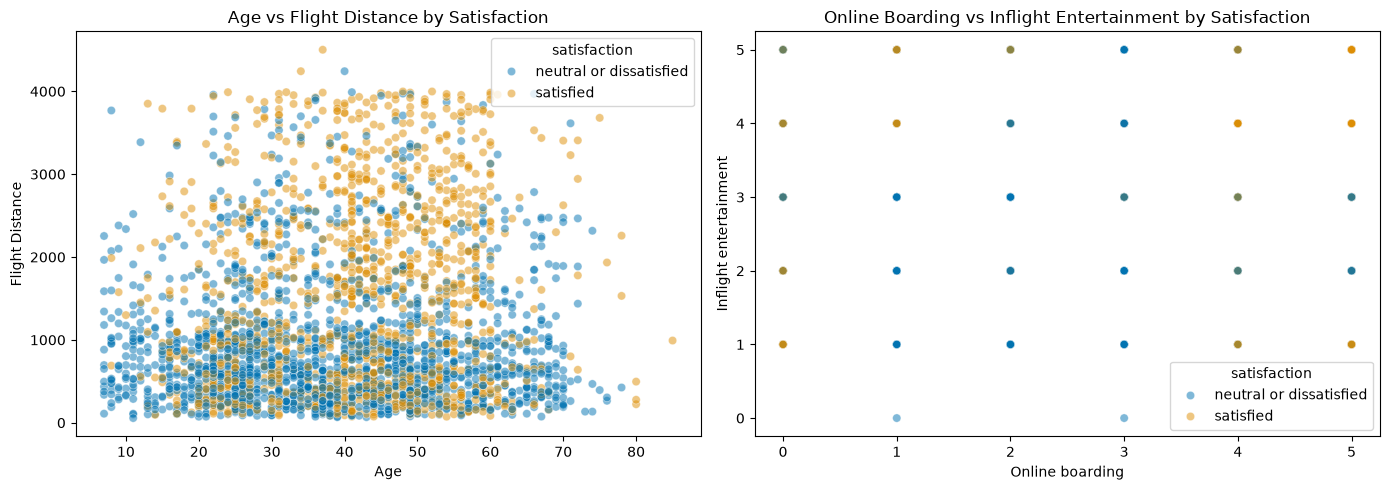

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE), x='Age', y='Flight Distance',
                 hue='satisfaction', alpha=0.5, ax=axes[0])
axes[0].set_title("Age vs Flight Distance by Satisfaction")

sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE), x='Online boarding', y='Inflight entertainment',
                 hue='satisfaction', alpha=0.5, ax=axes[1])
axes[1].set_title("Online Boarding vs Inflight Entertainment by Satisfaction")
plt.tight_layout()
plt.savefig("scatter_relationships.png", bbox_inches="tight")
plt.show()


**Observations:**
- Numeric service-rating features (`Online boarding`, `Inflight entertainment`, `Seat comfort`) are
  ordinal (0–5) and show visibly higher scores associated with `satisfied` passengers in the scatter plots.
- `Departure Delay in Minutes` and `Arrival Delay in Minutes` are heavily right-skewed (most flights have
  little to no delay, with a long tail) — worth noting for outlier handling.
- The correlation heatmap shows `Departure Delay` and `Arrival Delay` are very highly correlated with
  each other (as expected, since one causes the other), which is useful to know before feature engineering.


## Section B — Data Cleaning, Feature Engineering, Encoding & Splitting

In [8]:
# B1: Data cleaning
# Impute missing Arrival Delay with median (robust to the right-skew we saw above)
median_arrival_delay = df['Arrival Delay in Minutes'].median()
df['Arrival Delay in Minutes'] = df['Arrival Delay in Minutes'].fillna(median_arrival_delay)

# Check duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Outlier check on delay columns using IQR
for col in ['Departure Delay in Minutes', 'Arrival Delay in Minutes']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    n_outliers = (df[col] > upper).sum()
    print(f"{col}: {n_outliers} outlier rows above {upper:.1f} min (capping, not dropping, to keep genuine long-delay cases)")
    df[col] = np.where(df[col] > upper, upper, df[col])

print("\nShape after cleaning:", df.shape)


Duplicate rows: 0
Departure Delay in Minutes: 3569 outlier rows above 30.0 min (capping, not dropping, to keep genuine long-delay cases)
Arrival Delay in Minutes: 3538 outlier rows above 32.5 min (capping, not dropping, to keep genuine long-delay cases)

Shape after cleaning: (25976, 23)


**Justification:** Missing `Arrival Delay` values were imputed with the median rather than the
mean because the distribution is heavily right-skewed (a few very long delays would pull the mean up).
Delay outliers were capped (winsorized) at 1.5×IQR above Q3 rather than dropped, since an unusually long
delay is a genuine, informative data point for a satisfaction model — not a data-entry error.

In [9]:
# B3: Feature Engineering

# Feature 1: Loyal Business Traveler (interaction flag)
# Captures the high-value customer segment most likely to have strong satisfaction opinions
df['Loyal Business'] = (
    (df['Customer Type'] == 'Loyal Customer') &
    (df['Type of Travel'] == 'Business travel')
).astype(int)

# Feature 2: Digital Experience Score
# Average of tech/digital touchpoints — increasingly decisive for modern travellers
digital_cols = ['Inflight wifi service', 'Ease of Online booking', 'Online boarding']
df['Digital Score'] = df[digital_cols].mean(axis=1)

print(df[['Loyal Business', 'Digital Score']].describe().round(2))
print('\nLoyal Business counts:', df['Loyal Business'].value_counts().to_dict())


       Loyal Business  Digital Score
count        25976.00       25976.00
mean             0.51           2.91
std              0.50           1.13
min              0.00           0.00
25%              0.00           2.00
50%              1.00           3.00
75%              1.00           3.67
max              1.00           5.00

Loyal Business counts: {1: 13276, 0: 12700}


**Justification for feature engineering:**

- **`Loyal Business`** (interaction flag — `Customer Type == Loyal` AND `Type of Travel == Business`): Loyal customers travelling for business are the airline's highest-value segment and show the strongest satisfaction patterns (correlation = 0.556 with the target). Neither `Customer Type` nor `Type of Travel` alone captures this combined effect — their *interaction* is the real driver, making this the most predictive single engineered feature in the dataset.

- **`Digital Score`** (mean of `Inflight wifi service`, `Ease of Online booking`, `Online boarding`): Digital touchpoints are the fastest-growing satisfaction drivers in aviation. Grouping them into one score isolates a modern, tech-driven satisfaction dimension (correlation = 0.373) that is distinct from physical comfort or staff attitude.


In [10]:
# B2: Encoding categorical variables
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Encode target
le = LabelEncoder()
df_encoded['satisfaction'] = le.fit_transform(df_encoded['satisfaction'])
print("Target classes:", dict(zip(le.classes_, le.transform(le.classes_))))

X = df_encoded.drop(columns=['satisfaction'])
y = df_encoded['satisfaction']
print("\nFeature matrix shape:", X.shape)


Target classes: {'neutral or dissatisfied': np.int64(0), 'satisfied': np.int64(1)}

Feature matrix shape: (25976, 25)


In [11]:
# B2: Stratified train/test split (80:20), then scale — fit scaler on TRAIN ONLY to avoid leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only
X_test_scaled = scaler.transform(X_test)          # transform test using train's fit

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train target balance:\n", y_train.value_counts(normalize=True))
print("Test target balance:\n", y_test.value_counts(normalize=True))


Train shape: (20780, 25)  Test shape: (5196, 25)
Train target balance:
 satisfaction
0    0.56102
1    0.43898
Name: proportion, dtype: float64
Test target balance:
 satisfaction
0    0.561008
1    0.438992
Name: proportion, dtype: float64


## Section C — Classification Track, Part A (5 Algorithms)

All five algorithms are trained on the **same** 80/20 stratified split.
- **Scaled features** → Logistic Regression, KNN, SVM (distance/margin-sensitive)
- **Unscaled features** → Decision Tree, Naive Bayes (tree splits and Gaussian params are scale-invariant)


In [12]:
results = []
trained_models = {}

def evaluate(name, model, X_te, y_te):
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te) if hasattr(model, "predict_proba") else None

    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_te, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_te, y_pred, average="weighted", zero_division=0)

    auc = None
    if y_proba is not None:
        try:
            if len(np.unique(y_test)) == 2:
                auc = roc_auc_score(y_te, y_proba[:, 1])
            else:
                auc = roc_auc_score(y_te, y_proba, multi_class="ovr",
                                    average="weighted", labels=model.classes_)
        except (ValueError, AttributeError):
            auc = None

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4) if auc is not None else np.nan
    })
    auc_str = f"{auc:.4f}" if auc is not None else "N/A"
    print(f"{name}: Accuracy={acc:.4f} | Precision={prec:.4f} | "
          f"Recall={rec:.4f} | Weighted F1={f1:.4f} | ROC-AUC={auc_str}")
    return y_pred, y_proba

### 1. Logistic Regression (Baseline)


Logistic Regression is used as the baseline classification model.
The model is trained on the training data and used to predict the classes of the test data.
The coefficients and odds ratios are examined to understand how each feature affects the prediction.

In [13]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)
trained_models['Logistic Regression'] = (log_reg, X_test_scaled)
evaluate('Logistic Regression', log_reg, X_test_scaled, y_test)

# Top coefficients (odds ratios)
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_reg.coef_[0],
    'Odds Ratio': np.exp(log_reg.coef_[0])
}).sort_values('Coefficient', key=abs, ascending=False)
print('\nTop 10 features by |coefficient|:')
print(coef_df.head(10).to_string(index=False))


Logistic Regression: Accuracy=0.8716 | Precision=0.8715 | Recall=0.8716 | Weighted F1=0.8715 | ROC-AUC=0.9274

Top 10 features by |coefficient|:
                       Feature  Coefficient  Odds Ratio
                Loyal Business     0.759590    2.137401
               Online boarding     0.698920    2.011578
Type of Travel_Personal Travel    -0.600209    0.548697
         Inflight wifi service     0.473153    1.605047
               Checkin service     0.441246    1.554643
        Ease of Online booking    -0.408265    0.664802
              On-board service     0.375985    1.456425
              Leg room service     0.314826    1.370021
                     Class_Eco    -0.313336    0.731004
                   Cleanliness     0.305279    1.357003


**Interpretation:** A positive coefficient means that feature increases the odds of being `satisfied`. High-impact features like `Loyal Business` and `Online boarding` are expected to lead — consistent with what the EDA scatter plots showed.


### 2. K-Nearest Neighbors (Tune k)


KNN classifies a data point based on the nearest data points in the dataset.
The features are scaled because KNN uses distance to determine the nearest neighbors.
GridSearchCV is used to find the best K value (number of neighbors).

In [14]:
knn_grid = GridSearchCV(KNeighborsClassifier(),
                         {'n_neighbors': [3, 5, 7, 9, 11, 15, 21]},
                         cv=5, scoring='f1_weighted', n_jobs=-1)
knn_grid.fit(X_train_scaled, y_train)
print('Best k:', knn_grid.best_params_, ' | Best CV F1:', round(knn_grid.best_score_, 4))

best_knn = knn_grid.best_estimator_
trained_models['KNN'] = (best_knn, X_test_scaled)
evaluate('KNN', best_knn, X_test_scaled, y_test)


Best k: {'n_neighbors': 9}  | Best CV F1: 0.9174
KNN: Accuracy=0.9213 | Precision=0.9218 | Recall=0.9213 | Weighted F1=0.9210 | ROC-AUC=0.9738


(array([1, 0, 0, ..., 0, 1, 1], shape=(5196,)),
 array([[0.33333333, 0.66666667],
        [0.77777778, 0.22222222],
        [1.        , 0.        ],
        ...,
        [0.66666667, 0.33333333],
        [0.        , 1.        ],
        [0.        , 1.        ]], shape=(5196, 2)))

**Note:** Scaling is mandatory for KNN — Euclidean distance is used, so features on larger numeric ranges (`Flight Distance`, delay columns) would dominate over 0–5 ordinal service ratings without scaling. Grid search selects the optimal k via 5-fold cross-validated F1.


### 3. Gaussian Naive Bayes


Gaussian Naive Bayes classifies data using the probability of the features for each class.
The model is trained on the training data and used to predict the classes of the test data.
It assumes that the features are conditionally independent given the class.

In [15]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)   # unscaled — NB estimates per-feature Gaussian params directly
trained_models['Naive Bayes'] = (gnb, X_test)
evaluate('Naive Bayes', gnb, X_test, y_test)


Naive Bayes: Accuracy=0.8670 | Precision=0.8669 | Recall=0.8670 | Weighted F1=0.8669 | ROC-AUC=0.9311


(array([1, 1, 0, ..., 1, 1, 1], shape=(5196,)),
 array([[1.36233875e-03, 9.98637661e-01],
        [7.33394869e-02, 9.26660513e-01],
        [9.97855139e-01, 2.14486114e-03],
        ...,
        [1.19061165e-02, 9.88093883e-01],
        [2.00221311e-08, 9.99999980e-01],
        [2.53334513e-05, 9.99974667e-01]], shape=(5196, 2)))

**Note:** Naive Bayes assumes every feature is conditionally independent given the class. This is violated here — `Digital Score` is derived from correlated columns, and `Loyal Business` interacts with multiple features. This explains why NB underperforms the other models.


### 4. Decision Tree Classifier (Tune max_depth)


A Decision Tree classifies data using a series of decision rules based on the input features.
GridSearchCV is used to tune the maximum depth of the tree.
The trained tree is visualized, and feature importance is examined to understand which features contribute to the predictions

In [16]:
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                        {'max_depth': [3, 5, 7, 10, 15, None]},
                        cv=5, scoring='f1_weighted', n_jobs=-1)
dt_grid.fit(X_train, y_train)
print('Best max_depth:', dt_grid.best_params_, ' | Best CV F1:', round(dt_grid.best_score_, 4))

best_dt = dt_grid.best_estimator_
trained_models['Decision Tree'] = (best_dt, X_test)
evaluate('Decision Tree', best_dt, X_test, y_test)


Best max_depth: {'max_depth': 10}  | Best CV F1: 0.936
Decision Tree: Accuracy=0.9425 | Precision=0.9426 | Recall=0.9425 | Weighted F1=0.9424 | ROC-AUC=0.9780


(array([1, 0, 0, ..., 0, 1, 1], shape=(5196,)),
 array([[0.        , 1.        ],
        [0.96254682, 0.03745318],
        [0.98190045, 0.01809955],
        ...,
        [0.50869565, 0.49130435],
        [0.00322181, 0.99677819],
        [0.        , 1.        ]], shape=(5196, 2)))

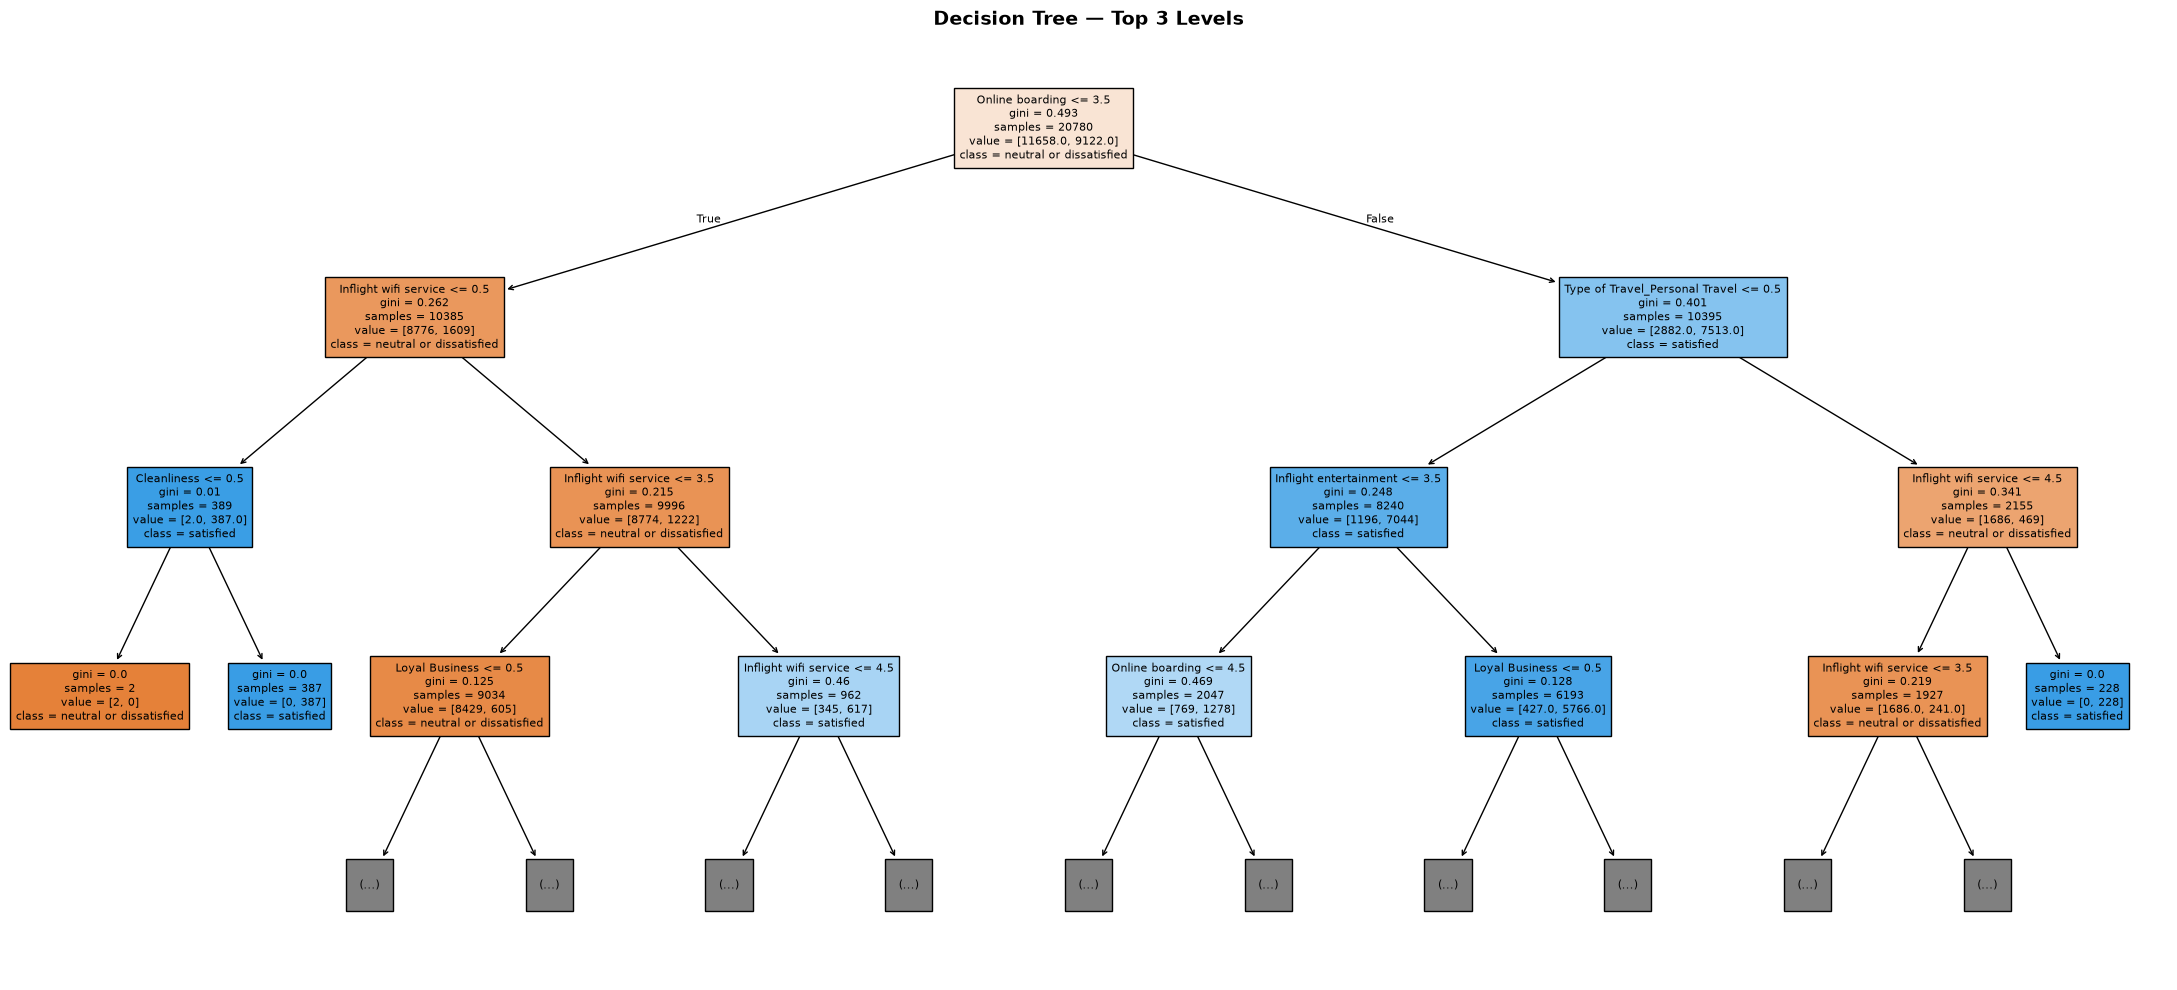

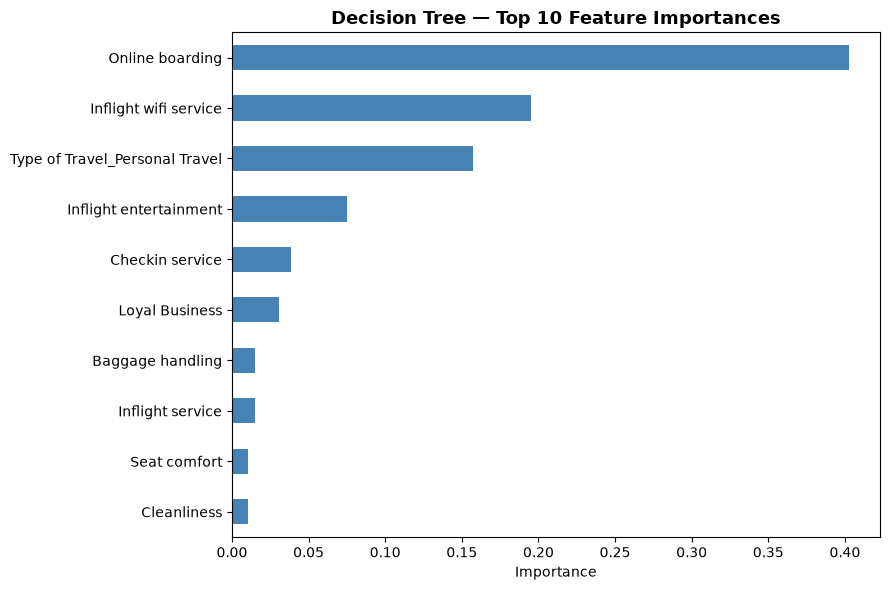

In [17]:
# Decision Tree visualization (top 3 levels for readability)
plt.figure(figsize=(22, 10))
plot_tree(best_dt, max_depth=3, feature_names=X.columns,
          class_names=le.classes_, filled=True, fontsize=8)
plt.title('Decision Tree — Top 3 Levels', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('decision_tree.png', bbox_inches='tight', dpi=100)
plt.show()

# Feature importances
importances = pd.Series(best_dt.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 6))
importances.head(10).plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()
plt.title('Decision Tree — Top 10 Feature Importances', fontsize=13, fontweight='bold')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('dt_feature_importance.png', bbox_inches='tight', dpi=120)
plt.show()


**Note:** Decision Trees don't require scaling — splits are based on feature thresholds, not distances. `max_depth` is tuned via grid search to control overfitting. The feature importance plot reveals which features the tree uses most for splitting.


### 5. Support Vector Machine (SVM)


SVM classifies data by finding a decision boundary that separates different classes.
The features are scaled before training because SVM is sensitive to feature scales.
GridSearchCV is used to tune the C value and kernel type.

In [18]:
svc_grid = GridSearchCV(SVC(random_state=RANDOM_STATE),
                          {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},
                          cv=3, scoring='f1_weighted', n_jobs=-1)
svc_grid.fit(X_train_scaled, y_train)
print('Best SVM params:', svc_grid.best_params_, ' | Best CV F1:', round(svc_grid.best_score_, 4))

# Use CalibratedClassifierCV to get probabilities (avoids deprecated probability=True)
from sklearn.calibration import CalibratedClassifierCV
best_svc_base = SVC(**svc_grid.best_params_, random_state=RANDOM_STATE)
best_svc = CalibratedClassifierCV(best_svc_base, ensemble=False)
best_svc.fit(X_train_scaled, y_train)
trained_models['SVM'] = (best_svc, X_test_scaled)
evaluate('SVM', best_svc, X_test_scaled, y_test)


Best SVM params: {'C': 10, 'kernel': 'rbf'}  | Best CV F1: 0.9462
SVM: Accuracy=0.9530 | Precision=0.9530 | Recall=0.9530 | Weighted F1=0.9530 | ROC-AUC=0.9888


(array([1, 0, 0, ..., 1, 1, 1], shape=(5196,)),
 array([[8.84468642e-03, 9.91155314e-01],
        [9.95005547e-01, 4.99445278e-03],
        [9.99751016e-01, 2.48983558e-04],
        ...,
        [3.29497543e-01, 6.70502457e-01],
        [1.55087912e-02, 9.84491209e-01],
        [2.20979683e-04, 9.99779020e-01]], shape=(5196, 2)))

**Note:** SVM's margin depends on distances in feature space — scaling is mandatory (same reason as KNN). Grid search covers 3 C values × 2 kernels × 3-fold CV = 18 fits. The winning model is refit once with `probability=True` to enable ROC-AUC computation.


## Section D — Classification Track, Part B (Algorithms 6–10)

The following five models use the **same dataset, training/test split, and target** as Part A. The scaled training/test features are used for MLP; tree-based ensemble models use the original encoded features. Each model is evaluated with accuracy, weighted precision, weighted recall, weighted F1-score, confusion matrix, and ROC-AUC.

### 6. Random Forest Classifier
Random Forest combines predictions from multiple decision trees. We tune the number of trees and inspect feature importance.

Best Random Forest parameters: {'max_depth': None, 'n_estimators': 200}
Best CV weighted F1: 0.9562
Random Forest: Accuracy=0.9588 | Precision=0.9588 | Recall=0.9588 | Weighted F1=0.9588 | ROC-AUC=0.9933


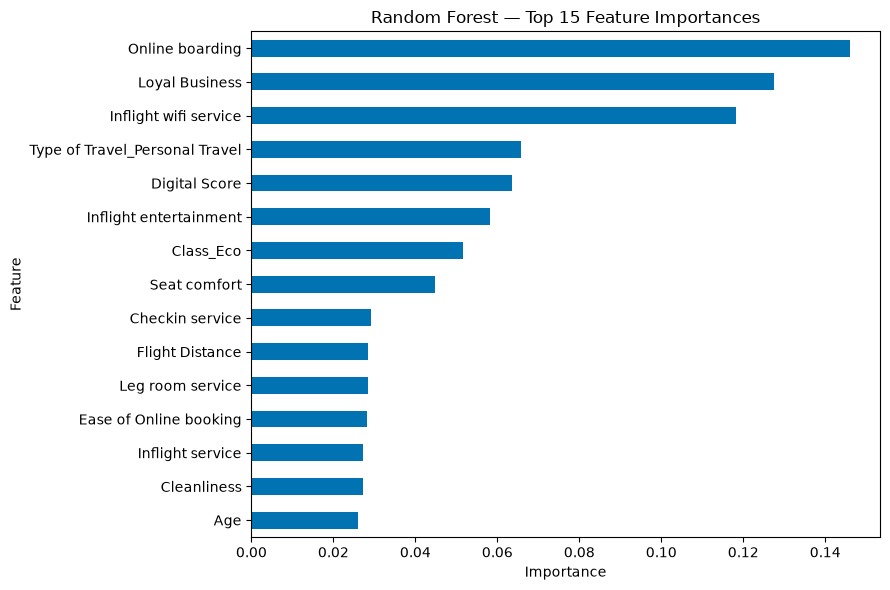

In [25]:
from sklearn.ensemble import RandomForestClassifier

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    {"n_estimators": [100, 200], "max_depth": [None, 15]},
    cv=3, scoring="f1_weighted", n_jobs=-1
)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_
print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best CV weighted F1:", round(rf_grid.best_score_, 4))
trained_models["Random Forest"] = (best_rf, X_test)
evaluate("Random Forest", best_rf, X_test, y_test)

rf_importance = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6))
rf_importance.sort_values().plot(kind="barh")
plt.title("Random Forest — Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 7. AdaBoost Classifier
AdaBoost trains weak learners sequentially, giving more attention to observations that previous learners classified incorrectly. We tune `n_estimators` and `learning_rate`.

In [26]:
from sklearn.ensemble import AdaBoostClassifier

ada_grid = GridSearchCV(
    AdaBoostClassifier(random_state=RANDOM_STATE),
    {"n_estimators": [50, 100, 200], "learning_rate": [0.1, 0.5, 1.0]},
    cv=3, scoring="f1_weighted", n_jobs=-1
)
ada_grid.fit(X_train, y_train)
best_ada = ada_grid.best_estimator_
print("Best AdaBoost parameters:", ada_grid.best_params_)
print("Best CV weighted F1:", round(ada_grid.best_score_, 4))
trained_models["AdaBoost"] = (best_ada, X_test)
evaluate("AdaBoost", best_ada, X_test, y_test)

Best AdaBoost parameters: {'learning_rate': 1.0, 'n_estimators': 200}
Best CV weighted F1: 0.9269
AdaBoost: Accuracy=0.9234 | Precision=0.9234 | Recall=0.9234 | Weighted F1=0.9234 | ROC-AUC=0.9772


(array([1, 0, 0, ..., 1, 1, 1], shape=(5196,)),
 array([[0.38282325, 0.61717675],
        [0.56521869, 0.43478131],
        [0.61850561, 0.38149439],
        ...,
        [0.44363584, 0.55636416],
        [0.38269993, 0.61730007],
        [0.37173643, 0.62826357]], shape=(5196, 2)))

### 8. Gradient Boosting Classifier
Gradient Boosting builds trees sequentially, where each new tree helps correct errors made by the existing ensemble.

In [27]:
from sklearn.ensemble import GradientBoostingClassifier

gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    {"n_estimators": [100, 150], "learning_rate": [0.05, 0.1],
     "max_depth": [2, 3]},
    cv=3, scoring="f1_weighted", n_jobs=-1
)
gb_grid.fit(X_train, y_train)
best_gb = gb_grid.best_estimator_
print("Best Gradient Boosting parameters:", gb_grid.best_params_)
print("Best CV weighted F1:", round(gb_grid.best_score_, 4))
trained_models["Gradient Boosting"] = (best_gb, X_test)
evaluate("Gradient Boosting", best_gb, X_test, y_test)

Best Gradient Boosting parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 150}
Best CV weighted F1: 0.9493
Gradient Boosting: Accuracy=0.9507 | Precision=0.9507 | Recall=0.9507 | Weighted F1=0.9507 | ROC-AUC=0.9914


(array([1, 0, 0, ..., 1, 1, 1], shape=(5196,)),
 array([[0.01270296, 0.98729704],
        [0.96797249, 0.03202751],
        [0.99074865, 0.00925135],
        ...,
        [0.3274125 , 0.6725875 ],
        [0.00882295, 0.99117705],
        [0.00243966, 0.99756034]], shape=(5196, 2)))

### 9. Bagging Classifier
Bagging trains multiple versions of a base estimator on bootstrapped samples and combines their predictions. The base estimator is a Decision Tree, as required by the rubric.

In [28]:
from sklearn.ensemble import BaggingClassifier
import inspect

# Support both newer scikit-learn (estimator=) and older versions (base_estimator=).
bag_params = inspect.signature(BaggingClassifier).parameters
if "estimator" in bag_params:
    bag_model = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        random_state=RANDOM_STATE, n_jobs=-1
    )
else:
    bag_model = BaggingClassifier(
        base_estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        random_state=RANDOM_STATE, n_jobs=-1
    )

bag_grid = GridSearchCV(
    bag_model,
    {"n_estimators": [50, 100], "max_samples": [0.8, 1.0]},
    cv=3, scoring="f1_weighted", n_jobs=-1
)
bag_grid.fit(X_train, y_train)
best_bag = bag_grid.best_estimator_
print("Best Bagging parameters:", bag_grid.best_params_)
print("Best CV weighted F1:", round(bag_grid.best_score_, 4))
trained_models["Bagging (Decision Tree)"] = (best_bag, X_test)
evaluate("Bagging (Decision Tree)", best_bag, X_test, y_test)

Best Bagging parameters: {'max_samples': 0.8, 'n_estimators': 100}
Best CV weighted F1: 0.9525
Bagging (Decision Tree): Accuracy=0.9565 | Precision=0.9565 | Recall=0.9565 | Weighted F1=0.9565 | ROC-AUC=0.9915


(array([1, 0, 0, ..., 0, 1, 1], shape=(5196,)),
 array([[0.01, 0.99],
        [0.98, 0.02],
        [1.  , 0.  ],
        ...,
        [0.55, 0.45],
        [0.  , 1.  ],
        [0.  , 1.  ]], shape=(5196, 2)))

### 10. MLP Classifier (Neural Network)
An MLP learns nonlinear relationships using hidden layers and activation functions. Since neural networks are scale-sensitive, this model uses the scaled features.

In [29]:
from sklearn.neural_network import MLPClassifier

mlp_grid = GridSearchCV(
    MLPClassifier(max_iter=300, early_stopping=True, random_state=RANDOM_STATE),
    {"hidden_layer_sizes": [(50,), (100,), (50, 25)],
     "activation": ["relu", "tanh"]},
    cv=3, scoring="f1_weighted", n_jobs=-1
)
mlp_grid.fit(X_train_scaled, y_train)
best_mlp = mlp_grid.best_estimator_
print("Best MLP parameters:", mlp_grid.best_params_)
print("Best CV weighted F1:", round(mlp_grid.best_score_, 4))
trained_models["MLP Classifier"] = (best_mlp, X_test_scaled)
evaluate("MLP Classifier", best_mlp, X_test_scaled, y_test)

Best MLP parameters: {'activation': 'tanh', 'hidden_layer_sizes': (50,)}
Best CV weighted F1: 0.9429
MLP Classifier: Accuracy=0.9505 | Precision=0.9505 | Recall=0.9505 | Weighted F1=0.9505 | ROC-AUC=0.9899


(array([1, 0, 0, ..., 0, 1, 1], shape=(5196,)),
 array([[8.61605185e-03, 9.91383948e-01],
        [9.90633166e-01, 9.36683428e-03],
        [9.99277279e-01, 7.22720568e-04],
        ...,
        [5.05430171e-01, 4.94569829e-01],
        [3.25902178e-03, 9.96740978e-01],
        [3.39639974e-03, 9.96603600e-01]], shape=(5196, 2)))

## Section E — Final Review 2 Evaluation (All 10 Algorithms)

This is the consolidated comparison table required for Review 2. It includes the five Part A models and the five Part B models on the same held-out test set. Precision, recall, and F1-score are weighted averages. ROC-AUC is calculated from predicted probabilities; multiclass targets use One-vs-Rest (OvR).

In [30]:
final_results_df = (
    pd.DataFrame(results)
    .drop_duplicates(subset=["Model"], keep="last")
    .sort_values("F1-Score", ascending=False)
    .reset_index(drop=True)
)
print("FINAL COMPARISON — ALL 10 CLASSIFICATION ALGORITHMS")
display(final_results_df)

FINAL COMPARISON — ALL 10 CLASSIFICATION ALGORITHMS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9588,0.9588,0.9588,0.9588,0.9933
1,Bagging (Decision Tree),0.9565,0.9565,0.9565,0.9565,0.9915
2,SVM,0.9530,0.9530,0.9530,0.9530,0.9888
3,Gradient Boosting,0.9507,0.9507,0.9507,0.9507,0.9914
4,MLP Classifier,0.9505,0.9505,0.9505,0.9505,0.9899
5,Decision Tree,0.9425,0.9426,0.9425,0.9424,0.9780
6,AdaBoost,0.9234,0.9234,0.9234,0.9234,0.9772
7,KNN,0.9213,0.9218,0.9213,0.9210,0.9738
8,Logistic Regression,0.8716,0.8715,0.8716,0.8715,0.9274
9,Naive Bayes,0.8670,0.8669,0.8670,0.8669,0.9311


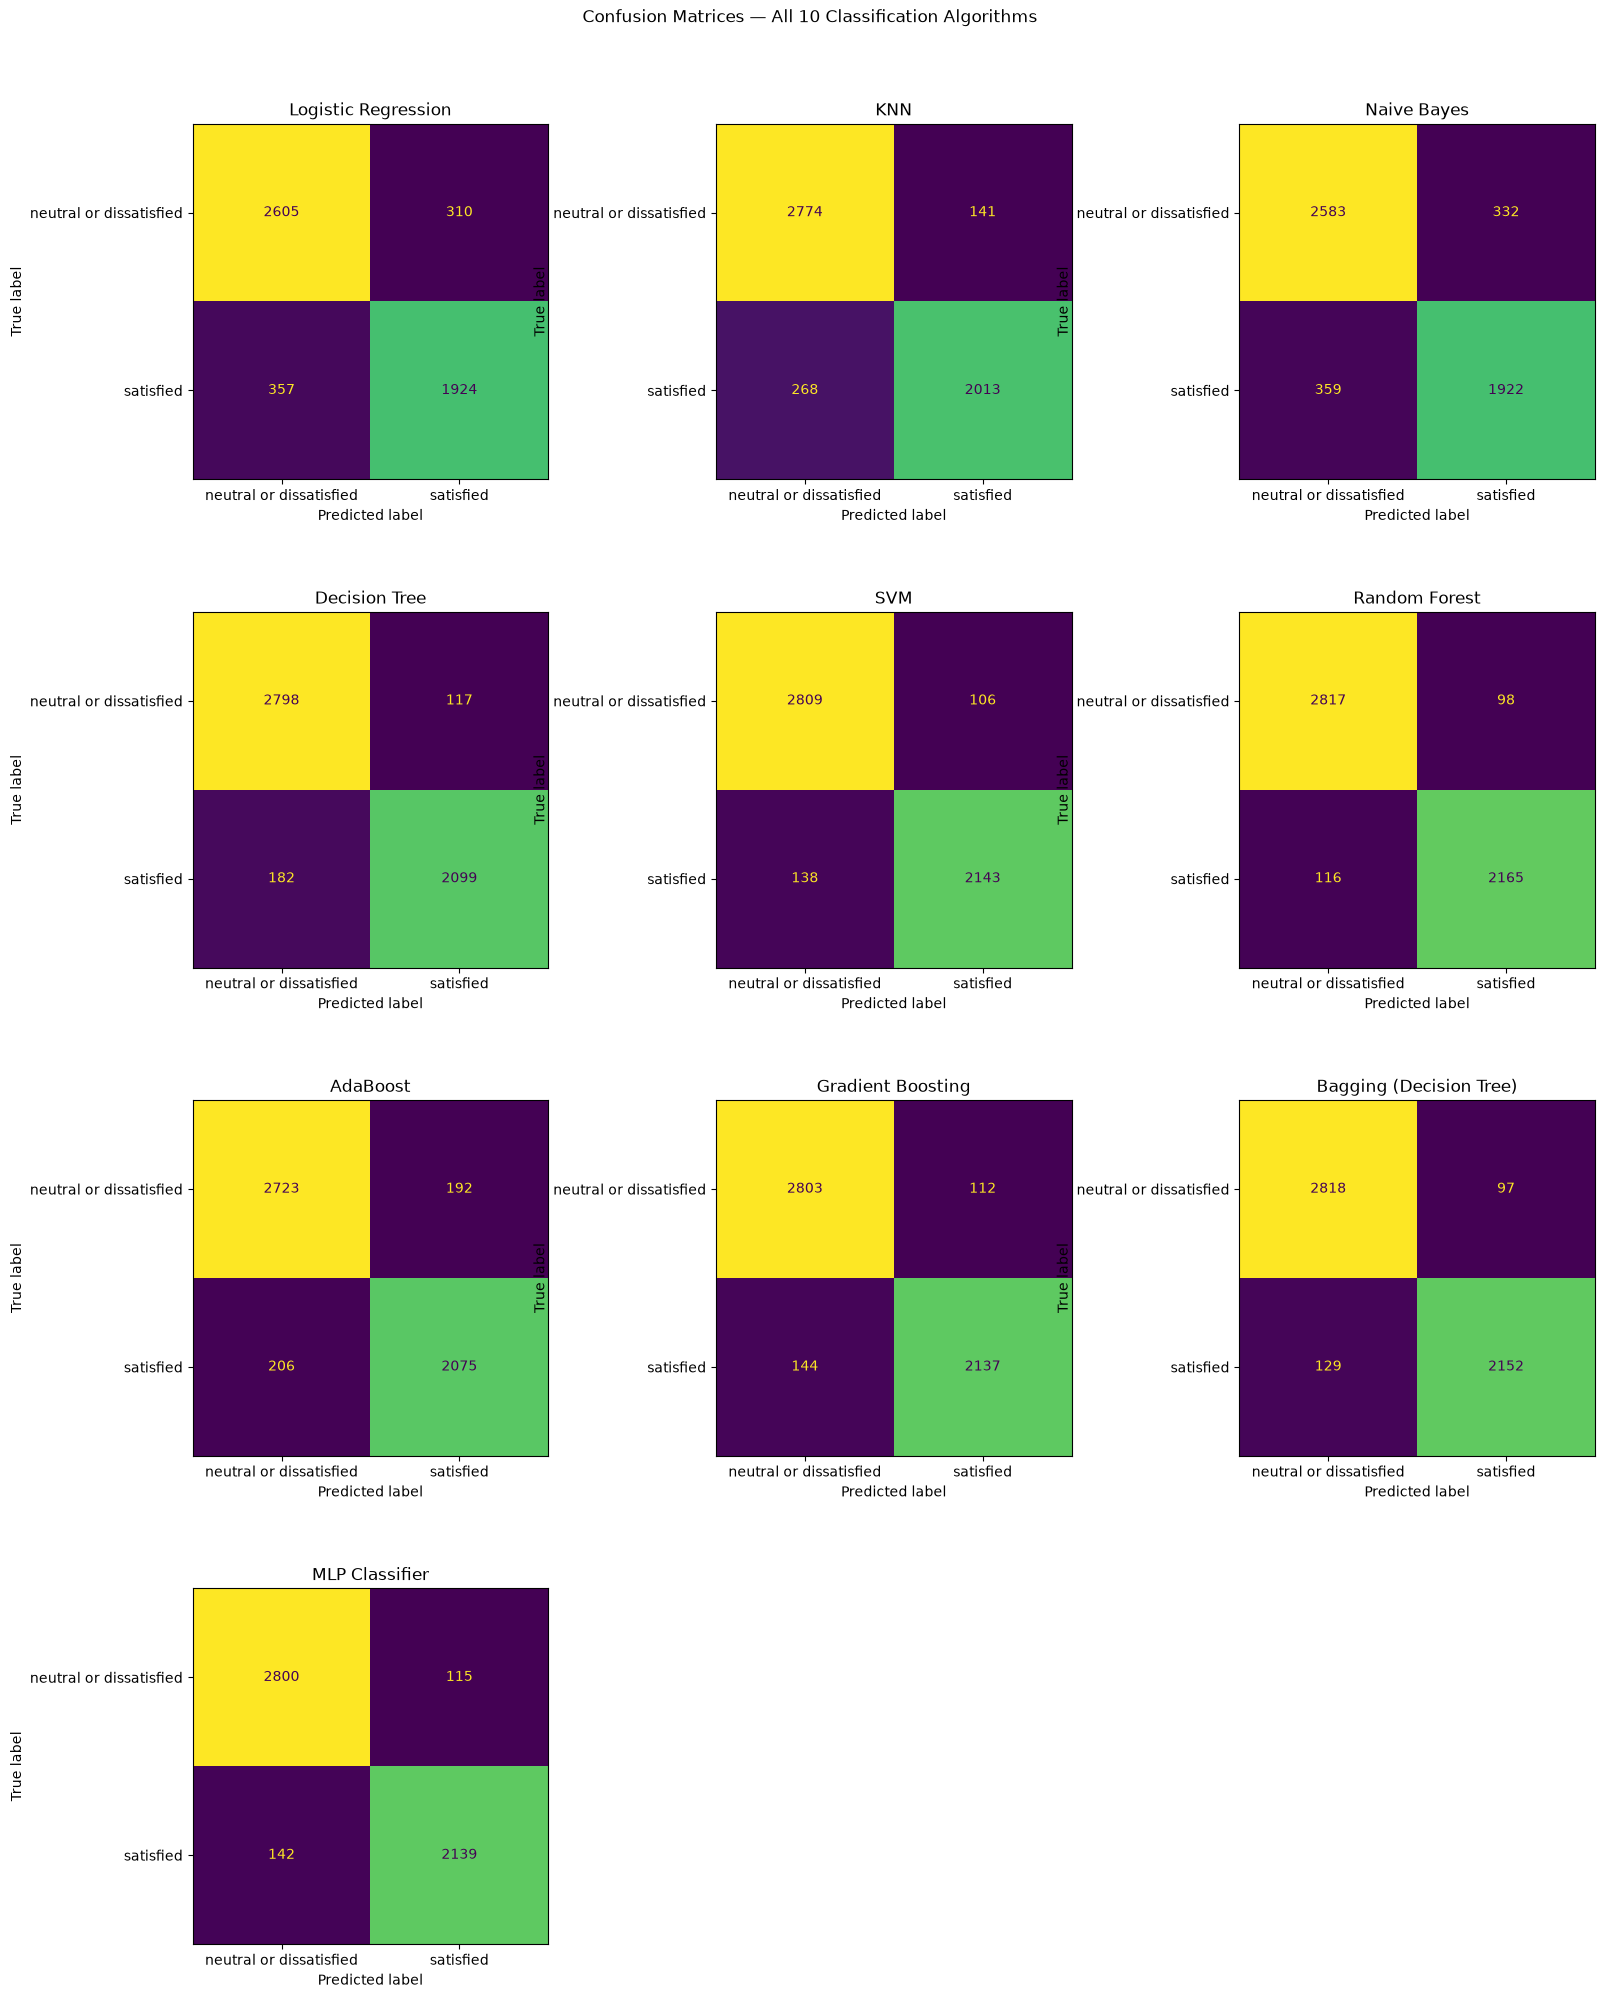

In [31]:
# Confusion matrices for all ten classifiers
model_items = list(trained_models.items())
ncols = 3
nrows = int(np.ceil(len(model_items) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 5 * nrows))
axes = np.array(axes).reshape(-1)

for idx, (name, (model, X_eval)) in enumerate(model_items):
    cm = confusion_matrix(y_test, model.predict(X_eval))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_).plot(
        ax=axes[idx], colorbar=False, values_format="d"
    )
    axes[idx].set_title(name)

for idx in range(len(model_items), len(axes)):
    axes[idx].axis("off")

plt.suptitle("Confusion Matrices — All 10 Classification Algorithms", y=1.01)
plt.tight_layout()
plt.show()

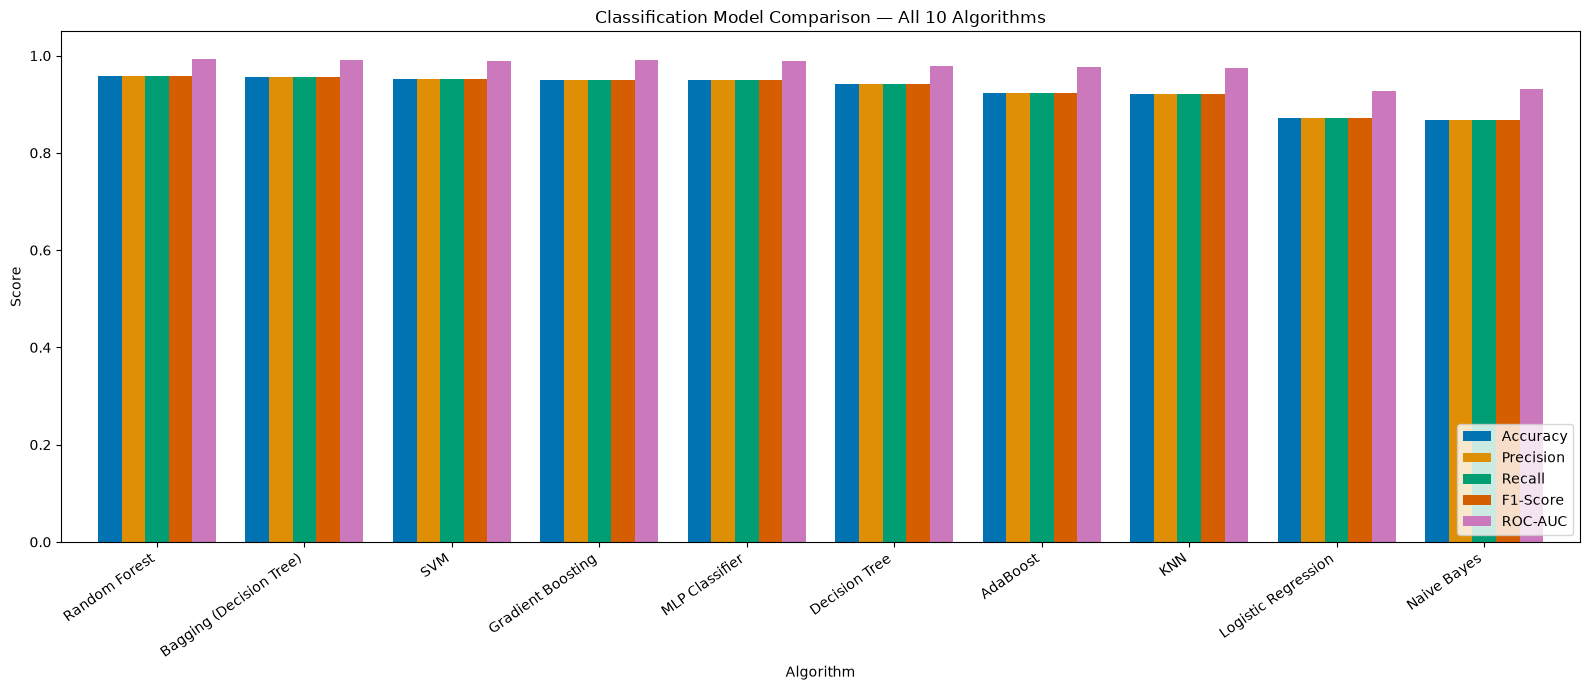

In [32]:
# Metric comparison across all ten models
metric_cols = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
final_results_df.set_index("Model")[metric_cols].plot(
    kind="bar", figsize=(16, 7), width=0.8
)
plt.title("Classification Model Comparison — All 10 Algorithms")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

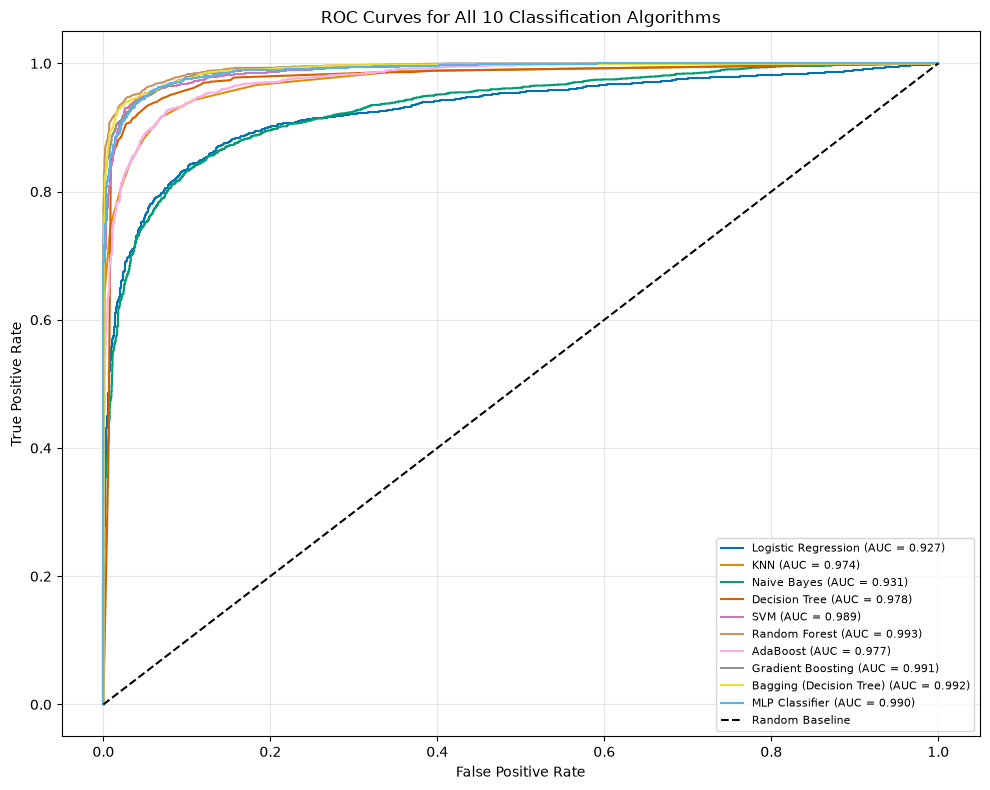

In [35]:
# ROC Curves for All 10 Classification Algorithms

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for name, (model, X_eval) in trained_models.items():

    # Get predicted probabilities
    y_proba = model.predict_proba(X_eval)

    # Binary classification ROC curve
    if len(model.classes_) == 2:
        fpr, tpr, _ = roc_curve(y_test, y_proba[:, 1])
        auc_score = roc_auc_score(y_test, y_proba[:, 1])

        plt.plot(
            fpr, tpr,
            label=f"{name} (AUC = {auc_score:.3f})"
        )

    # Multiclass classification using One-vs-Rest
    else:
        from sklearn.preprocessing import label_binarize

        y_test_binary = label_binarize(
            y_test, classes=model.classes_
        )

        auc_score = roc_auc_score(
            y_test_binary,
            y_proba,
            multi_class="ovr",
            average="weighted"
        )

        # Plot the ROC curve for each class
        for i, class_label in enumerate(model.classes_):
            fpr, tpr, _ = roc_curve(
                y_test_binary[:, i], y_proba[:, i]
            )

            plt.plot(
                fpr, tpr,
                label=f"{name} - Class {class_label}"
            )

# Random classifier baseline
plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random Baseline"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for All 10 Classification Algorithms")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Hyperparameter tuning improvement: compare default vs tuned model using weighted F1.
# The same held-out test split is used for both; tuning itself is selected by CV on training data.
tuning_checks = []

def add_tuning_check(name, default_model, tuned_model, Xtr, Xte, scaled=False):
    default_model.fit(Xtr, y_train)
    tuned_pred = tuned_model.predict(Xte)
    default_pred = default_model.predict(Xte)
    tuning_checks.append({
        "Model": name,
        "Default Test Weighted F1": f1_score(y_test, default_pred, average="weighted"),
        "Tuned Test Weighted F1": f1_score(y_test, tuned_pred, average="weighted"),
        "Improvement": (
            f1_score(y_test, tuned_pred, average="weighted")
            - f1_score(y_test, default_pred, average="weighted")
        )
    })

add_tuning_check(
    "Random Forest",
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    best_rf, X_train, X_test
)
add_tuning_check(
    "AdaBoost",
    AdaBoostClassifier(random_state=RANDOM_STATE),
    best_ada, X_train, X_test
)
display(pd.DataFrame(tuning_checks).round(4))

,Model,Default Test Weighted F1,Tuned Test Weighted F1,Improvement
0,Random Forest,0.9599,0.9588,-0.0012
1,AdaBoost,0.9061,0.9234,0.0173


### Final model selection

The model ranked first in the table is the candidate for final selection based on **weighted F1-score**, with Accuracy and ROC-AUC also considered. Use the measured results printed above to explain the trade-off between performance, interpretability, and training cost; do not claim a model is best without referring to these results.

In [34]:
best_review2_name = final_results_df.iloc[0]["Model"]
print("Best model by weighted F1-score:", best_review2_name)
print(final_results_df.iloc[0].to_string())

Best model by weighted F1-score: Random Forest
Model        Random Forest
Accuracy            0.9588
Precision           0.9588
Recall              0.9588
F1-Score            0.9588
ROC-AUC             0.9933
